# Veri Temizleme ve Keşfedici Analiz

Gerçek veri, ders kitaplarındaki gibi düzgün gelmez: bazı hücreler boştur, bazıları imkânsız değerler taşır, bazıları yanlış yazılmıştır. **Keşfedici veri analizi (exploratory data analysis, EDA)**, veriyi çizmeden ve modellemeden önce tanıma sürecidir; bu derste EDA akışını yürütecek, tablodaki sorunları sistematik olarak bulacak ve temizleyeceksin. Çalışacağın veri, bir kahve zincirine yapılan müşteri anketi — ve bilerek kirli bırakıldı.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- Bir tabloyu EDA akışıyla incelemek (`info`, `describe`, `isna`, `value_counts`)
- Eksik değerleri (missing value) bulup doldurma ya da düşürme kararı vermek
- Aykırı değerleri (outlier) fark edip gerektiğinde ayıklamak
- Tutarsız kategori adlarını ve bozuk veri türlerini düzeltmek
- Yinelenen satırları kaldırmak ve her temizlik kararını gerekçelendirmek

Bu ders, kursun 6. öğrenme çıktısının tamamını karşılıyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Veri dünyasında ünlü bir söz vardır: "Çöp içeri, çöp dışarı." Kirli bir tabloyla çizilen grafik, ne kadar güzel tasarlanırsa tasarlanansın yanlış bir hikâye anlatır. Ortalama yaşı -3 çıkan bir müşteri tablosundan "müşteri profilimiz genç" sonucu çıkarmak, 1. dersteki yanıltıcı grafiklerden daha tehlikelidir: bu kez yanıltılan grafik değil, sensin.

İyi haber şu: sorunların büyük bölümü birkaç kalıba girer (eksik, aykırı, tutarsız, bozuk tür, yinelenen) ve hepsi birkaç pandas komutuyla yakalanır. Bu dersten sonra 7. derste çizeceğin her grafik, bugün öğrendiğin kontrol alışkanlığıyla başlayacak.

## 🔗 Ön Bilgi

- [pandas DataFrame](05-Pandas-Dataframe.ipynb): yükleme, seçme, filtreleme, gruplama. Bu ders, o araçları sorun avlamaya çeviriyor.

## 🔍 Birlikte Keşfedelim

Anket verisi `../Data/06-survey-dirty.csv` dosyasında: 40 müşteri, şehir, yaş, haftalık kahve tüketimi ve memnuniyet puanı sorulmuş.

**Tahminin:** Dosyayı yükleyip `head()` ile ilk satırlara baktın; her şey düzgün görünüyor. "Bu tablo temizdir" diyebilir misin? Hangi kontrolleri yapmadan neden söyleyemezsin? Tahminini bu hücreye yaz.

İlk bakış:

In [1]:
import pandas as pd

anket = pd.read_csv("../Data/06-survey-dirty.csv")
anket.head()

,id,sehir,yas,haftalik_kahve,memnuniyet
0,1,İstanbul,34.0,7.0,4
1,2,İstanbul,28.0,12.0,5
2,3,istanbul,41.0,3.0,3
3,4,İstanbul,NaN,5.0,4
4,5,İSTANBUL,23.0,10.0,5


İlk beş satır gerçekten de düzgün görünüyor. Ama ilk bakış, veri temizlikte en az güvenilir araçtır. Şimdi standart EDA komutlarını çalıştır; özellikle sayısal özetlere dikkat et:

In [2]:
anket.info()

<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              41 non-null     int64  
 1   sehir           41 non-null     str    
 2   yas             39 non-null     float64
 3   haftalik_kahve  39 non-null     float64
 4   memnuniyet      41 non-null     str    
dtypes: float64(2), int64(1), str(2)
memory usage: 1.7 KB


In [3]:
anket.describe()

,id,yas,haftalik_kahve
count,41.000000,39.000000,39.000000
mean,20.292683,40.384615,13.974359
std,11.619475,29.139967,47.126642
min,1.000000,-3.000000,1.000000
25%,11.000000,28.500000,4.000000
50%,20.000000,35.000000,6.000000
75%,30.000000,44.500000,8.500000
max,40.000000,200.000000,300.000000


**Gözlem:** İşte yakaladıklarımız:

- `yas` sütununun minimumu **-3**, maksimumu **200**. Yaşı -3 olan müşteri olamaz; bu bir hata.
- `haftalik_kahve` maksimumu **300**: haftada 300 fincan, günde 43 fincan demek. Aykırı değer.
- `count` satırına göre `yas` 39, `haftalik_kahve` 39, yani 41 satırdan bazıları **eksik**.
- `memnuniyet` sütunu `describe()` özetine hiç girmiyor! Neden? Çünkü sütun sayısal değil, `object` (metin) olarak okunmuş — içinde sayı olmayan bir şey var.

Dört bakışta dört sorun türü. Şimdi bunları tek tek ve sistemli olarak ele alacağız.

## 📖 Kavramlar

**Keşfedici veri analizi (EDA):** Veriyi tanıma ve özetleme süreci. Amaçları: sorunları belirlemek, değişkenlerin aralığını ve dağılımını görmek, ileride yapılacak görselleştirme ya da analiz için yön çizmek. EDA, hipotez doğrulama değil keşif işidir; "acaba ..." soruları sorarsın.

**Eksik değer (missing value):** Boş bırakılmış hücre. pandas bunları `NaN` (not a number) ile gösterir; `isna()` ile bulunur. İki temel strateji: **doldurmak** (ortalama/medyan gibi bir değerle) ya da **düşürmek** (satırı atlamak). Karar, eksikliğin oranına ve sorunun niteliğine bağlıdır.

**Aykırı değer (outlier):** Diğerlerinden çok farklı, genellikle imkânsız ya da şüpheli değer. Yaşta -3 ve 200 bunlar. Aykırı değer her zaman hata değildir (gerçekten olağanüstü bir müşteri olabilir); ama imkânsızsa hata olduğuna karar verirsin.

**Tutarsız kategori:** Aynı şehrin "İstanbul", "istanbul", "İSTANBUL" olarak yazılması. Gruplama yaparsan aynı şehir üç farklı grup olur; filtre "sessiz boş sonuç" döndürür (5. dersin dersi).

**Bozuk veri türü:** Sayı beklenen sütunda metin olması. `describe()`'ın sütunu görmezden gelmesi ve `dtypes`'ta `object` görünmesi klasik belirtisidir.

**Yinelenen satır:** Aynı gözlemin iki kez kaydedilmesi; toplamları ve sayıları şişirir.

## 🛠️ Uygulama

### 1) Eksik değerleri bul

`isna()` her hücre için True/False üretir; `.sum()` ile sütun bazında toplarız:

In [4]:
anket.isna().sum()

id                0
sehir             0
yas               2
haftalik_kahve    2
memnuniyet        0
dtype: int64

`id` ve `sehir` tam; `yas`'ta 2, `haftalik_kahve`'de 2 eksik var. Eksik satırları görmek istersek:

In [5]:
anket[anket["yas"].isna()]

,id,sehir,yas,haftalik_kahve,memnuniyet
3,4,İstanbul,NaN,5.0,4
10,11,Ankara,NaN,8.0,4


### 2) Aykırı değerleri yakala

Sayısal özet bize ipini verdi; şimdi o satırları filtreyle görelim:

In [6]:
anket[(anket["yas"] < 15) | (anket["yas"] > 90)]

,id,sehir,yas,haftalik_kahve,memnuniyet
8,9,Ankara,-3.0,6.0,5
13,14,İzmir,200.0,4.0,3


In [7]:
anket[anket["haftalik_kahve"] > 30]

,id,sehir,yas,haftalik_kahve,memnuniyet
15,16,İzmir,24.0,300.0,5


### 3) Tutarsız kategorileri düzelt

Şehir sütunundaki benzersiz değerlere bak:

In [8]:
anket["sehir"].value_counts()

sehir
İstanbul    12
Ankara      12
İzmir       12
istanbul     2
İSTANBUL     1
ANKARA       1
izmir        1
Name: count, dtype: int64

Aynı üç şehir, altı farklı yazımla karşımıza çıktı. Düzeltmek için bir eşleme sözlüğü kullanacağız; her yanlış yazımı doğru karşılığına çeviriyoruz:

In [9]:
duzeltme = {
    "istanbul": "İstanbul",
    "İSTANBUL": "İstanbul",
    "ANKARA": "Ankara",
    "izmir": "İzmir",
}

anket["sehir"] = anket["sehir"].replace(duzeltme)
anket["sehir"].value_counts()

sehir
İstanbul    15
Ankara      13
İzmir       13
Name: count, dtype: int64

Artık üç şehir var ve sayılar toplandı. Bu düzeltme yapılmadan `groupby("sehir")` yapsaydık aynı şehirler ayrı gruplara düşecekti.

### 4) Bozuk türü düzelt

`memnuniyet` sütununda sayı olması gerekirken metin karışmış. Önce bozuk satırları bulalım, sonra sütunu sayıya çevirelim:

In [10]:
anket["memnuniyet"].unique()

<StringArray>
['4', '5', '3', '2', 'iyi']
Length: 5, dtype: str

In [11]:
anket["memnuniyet"] = pd.to_numeric(anket["memnuniyet"], errors="coerce")
anket["memnuniyet"].unique()

array([ 4.,  5.,  3.,  2., nan])

`errors="coerce"` sayesinde çevrilemeyen değerler ("iyi") sessizce `NaN` oldu. Ama dikkat: sessizce! Bu yüzden çevirmeden önce `unique()` ile ne olduğunu görmek, çevirdikten sonra kaç `NaN` çıktığını kontrol etmek iyi bir alışkanlıktır. "İyi" bir memnuniyet puanı değil; bu iki müşterinin puanı olmadığına karar verip doldurmayacağız.

### 5) Yinelenen satırları kaldır

In [12]:
anket[anket.duplicated(keep=False)]

,id,sehir,yas,haftalik_kahve,memnuniyet
11,12,İzmir,31.0,5.0,4.0
40,12,İzmir,31.0,5.0,4.0


In [13]:
anket = anket.drop_duplicates()
anket.shape

(40, 5)

41 satırdan 40'a düştük: 12 numaralı müşteri iki kez kaydedilmişti.

### 6) Temizlik kararlarını uygula

Şimdiye kadar sorunları **bulduk**. Temizlik, bulgulara karar vermektir ve her karar gerekçesiz uygulanmamalı:

- **Yaş -3 ve 200:** İmkânsız değerler; düzeltmek için bilgi yok → satırları düşürüyoruz.
- **Haftalık kahve 300:** Günde 43 fincan fiziksel olarak anlamlı değil; büyük olasılıkla 30 yazılmak istendi ama bilemeyiz → satırı düşürüyoruz.
- **Yaş eksik (2 satır):** Yaş bu anketin merkezî değişkeni değil; medyanla doldurmak makul → dolduruyoruz.
- **Kahve eksik (2 satır):** Oran küçük; medyanla dolduruyoruz.
- **Memnuniyet "iyi" (2 satır):** Sayıya çevrilemedi, puan yok → NaN kalıyor; memnuniyet analizi yaparken eksikler otomatik atlanır.

Doldurmayı düşürmeden önce yapıyoruz; çünkü medyan, tabloda hâlâ duran aykırı değerlerden (-3, 200, 300) pek etkilenmez, aykırılara duyarlı olan ortalama değildir. Kararları koda dökelim:

In [14]:
# 1) Eksik yaş ve kahve değerlerini medyanla doldur
temiz = anket.copy()
temiz["yas"] = temiz["yas"].fillna(temiz["yas"].median())
temiz["haftalik_kahve"] = temiz["haftalik_kahve"].fillna(temiz["haftalik_kahve"].median())

# 2) İmkânsız yaşları ve aşırı kahve değerini düşür
temiz = temiz[(temiz["yas"] > 15) & (temiz["yas"] < 90)]
temiz = temiz[temiz["haftalik_kahve"] < 30]

temiz.describe()

,id,yas,haftalik_kahve,memnuniyet
count,37.000000,37.000000,37.000000,35.000000
mean,21.108108,37.675676,6.540541,3.828571
std,11.927521,10.964093,3.428594,0.890661
min,1.000000,22.000000,1.000000,2.000000
25%,11.000000,29.000000,4.000000,3.000000
50%,22.000000,35.500000,6.000000,4.000000
75%,31.000000,44.000000,8.000000,4.000000
max,40.000000,65.000000,15.000000,5.000000


### 7) Öncesi/sonrası karşılaştırması

Temizliğin etkisini görmenin en hızlı yolu, aynı özeti iki durumda yan yana görmektir. Yaş dağılımına bir histogram çizelim (histogramı 7. derste ayrıntılı öğreneceğiz; şimdilik "değerleri aralıklara dizer" bilgisi yeterli):

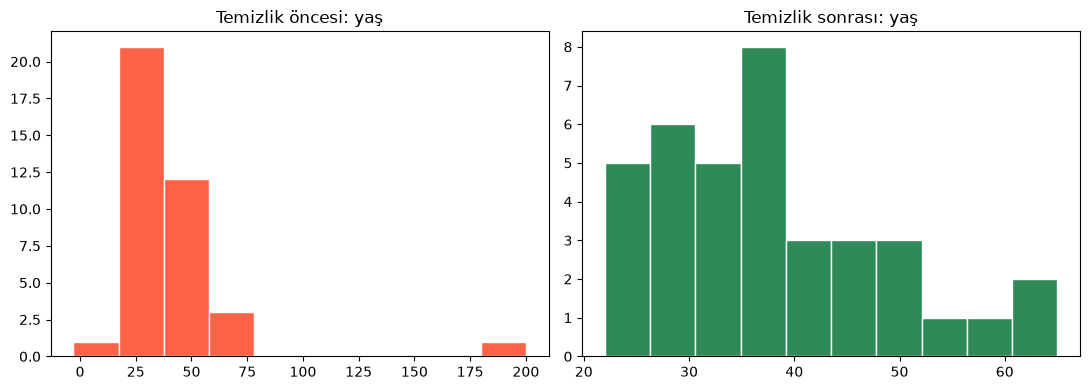

In [15]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(anket["yas"].dropna(), bins=10, color="tomato", edgecolor="white")
ax1.set_title("Temizlik öncesi: yaş")

ax2.hist(temiz["yas"], bins=10, color="seagreen", edgecolor="white")
ax2.set_title("Temizlik sonrası: yaş")

plt.tight_layout()
plt.show()

**Gözlem:** Soldaki grafikte -3 ve 200 değerleri yüzünden tüm gerçek dağılım 0'ın civarına sıkışmış; 20-65 aralığındaki asıl örüntü okunamıyor. Sağdaki grafik aynı verinin temizlenmiş hâli: dağılım artık görünür. Kirli veri, grafikte kendini böyle belli eder.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** Eksik yaşları medyan yerine 0 ile doldursaydık ne olurdu? Tahmin et, sonra dene:

In [16]:
kotu_doldurma = anket.copy()
kotu_doldurma["yas"] = kotu_doldurma["yas"].fillna(0)

print("Doğru (medyan) ortalama yaş:", round(temiz["yas"].mean(), 1))
print("Yanlış (0) ortalama yaş:", round(kotu_doldurma["yas"].mean(), 1))

Doğru (medyan) ortalama yaş: 37.7
Yanlış (0) ortalama yaş: 38.6


**Gözlem:** 0 ile doldurmak ortalamayı belirgin biçimde düşürdü. "0 yaş" diye bir müşteri olmadığı için bu doldurma, veriye **yeni bir yalan** ekledi. Doldurma değerinin gerçekçi olması (medyan, ortalama ya da alana uygun bir varsayım) bu yüzden önemlidir.

**Deney 2:** `describe()`'ta min/max dışında hangi değerler aykırıya işaret eder? `haftalik_kahve` için `describe()` çıktısındaki çeyrek değerlere bak (25%, 50%, 75%) ve medyanla maksimumu karşılaştır. Aradaki sıçrama ne anlatıyor?

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| Sütun `describe()`'ta görünmüyor | Tür `object` (metin karışmış) | `unique()` ile içine bak; `pd.to_numeric(..., errors="coerce")` |
| `SettingWithCopyWarning` | Filtrelenmiş kopya üzerinde atama | `temiz = anket[koşul].copy()` gibi açık kopya al |
| Grup sayısı beklenenden fazla | Tutarsız kategori adları | `value_counts()` ile yazımları karşılaştır, `replace` ile eşle |
| Ortalama beklenmedik derecede düşük/yüksek | Aykırı ya da eksik yerine konan uydurma değer | `describe()`'ta min/max'e bak; doldurma değerini gözden geçir |
| `KeyError` sütun adında | Yazım/Türkçe karakter farkı | `list(df.columns)` ile gerçek adlara bak |

> **İpucu:** Her temizlik adımından sonra tabloyu yeniden özetlemek (`describe()`, `shape`) işlemin etkisini görmenin en kolay yoludur. Bu dersteki öncesi/sonrası karşılaştırması bunun kalıcı hâli olsun.

## 🏋️ Kendin Dene

`temiz` tablosuyla aşağıdaki soruları yanıtla:

1. Şehir bazında ortalama memnuniyet nedir? (`groupby` + `mean`; `memnuniyet`'teki eksikler gruplamada otomatik atlanır.)
2. Haftalık kahve tüketimi 8 fincan ve üzeri olan müşterilerin oranı nedir? (Filtre + `shape[0]`, bölmeyi `len`'e.)
3. Yaşı 40 üstü müşterilerin ortalama haftalık kahve tüketimi, 40 altındakilerden farklı mı?
4. **TODO:** `temiz` tablosuna `aylik_harcama` adlı bir sütun ekle: haftalık fincan sayısının 4 hafta ve fincan başına 60 TL ile çarpımı. Sonra şehir bazında toplam aylık harcamayı hesapla.

<details>
<summary>İpucu</summary>

Sütun türetmeyi 5. dersten hatırla: `temiz["aylik_harcama"] = temiz["haftalik_kahve"] * 4 * 60`. Grup toplamı için `groupby("sehir")["aylik_harcama"].sum()`.

</details>

## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. EDA'nın amacı nedir ve görselleştirmeden önce neden yapılır? İki cümleyle açıkla.
2. `anket.isna().sum()` ifadesi adım adım ne yapar?
3. Eksik bir değerle karşılaştığında doldurma ve düşürme arasında nasıl seçim yaparsın? Kararı etkileyen iki etken yaz.
4. `memnuniyet` sütunu `describe()` özetinde neden görünmedi?
5. "Yaş -3" ile "haftalık 300 fincan" arasındaki fark nedir? İkisi de aykırı mı, biri hata mı?
6. Temizlenmiş tabloda yinelenen satır kalmadığını hangi komutla doğrularsın?

## 🚀 Bağımsız Çalışma

- **Açık veri avı:** Açık veri portallarından (ör. Kaggle, İBB açık veri portalı) ilgilendiğin küçük bir CSV bul. Bugünkü EDA akışını uygula: `info`, `describe`, `isna`, `value_counts`, `duplicated`. Bulduğun sorunları ve verdiğin kararları kısa bir not defterine yaz.
- **Karar günlüğü:** Bu derste verdiğimiz temizlik kararlarının bir listesini çıkar ve her birine tek cümlelik gerekçe yaz. Bu alışkanlık, ileride kendi projende (16. ders) raporunun en değerli bölümü olacak.

## 📚 Daha Fazlasını Öğrenmek

- pandas eksik veri rehberi: https://pandas.pydata.org/docs/user_guide/missing_data.html
- pandas yinelenen veriler: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html

İngilizcedir; komut örnekleri doğrudan denenebilir.

## ✅ Kısa Özet

- EDA, veriyi analiz ve görselleştirme öncesinde tanıma sürecidir; ilk bakış yetmez, özet komutları gerekir.
- Eksik değerler `isna().sum()` ile bulunur; doldurma (medyan/ortalama) ya da düşürme kararı, orana ve değişkenin önemine göre verilir.
- Aykırı değerler `describe()`'ın min/max'i ve çeyrek sıçramalarıyla fark edilir; imkânsız olanlar düşürülür, karar gerekçelendirilir.
- Tutarsız kategoriler `value_counts()` ile yakalanır ve `replace` eşlemesiyle düzeltilir.
- Bozuk türler `pd.to_numeric(..., errors="coerce")` ile onarılır; çevrilemeyenler `NaN` olur, sessizliği kontrol et.
- Yinelenen satırlar `duplicated()` ile bulunur, `drop_duplicates()` ile kaldırılır.
- Temizlik öncesi/sonrası özet ve grafik karşılaştırması, kararların etkisini görünür kılar.

Sıradaki derste artık temiz veriyi grafiklere dökmenin zamanı: matplotlib ile çizgi, çubuk ve dağılım grafikleri.

---

[← Önceki ders: pandas DataFrame](05-Pandas-Dataframe.ipynb) · [Sıradaki ders: Matplotlib Temelleri →](07-Matplotlib-Basics.ipynb)

## Cevaplar

<details>
<summary>Kendin Dene: aylık harcama (TODO çözümü)</summary>

```python
temiz["aylik_harcama"] = temiz["haftalik_kahve"] * 4 * 60
temiz.groupby("sehir")["aylik_harcama"].sum()
```

Şehir bazında toplamlar İstanbul lehine belirgin farkla dağılır; müşteri sayıları da benzer orandadır.

</details>

<details>
<summary>Kontrol Et 1</summary>

EDA, verinin yapısını, aralıklarını, eksiklerini ve tuhaflıklarını keşfetmektir. Görselleştirmeden önce yapılır çünkü kirli ya da yanlış anlaşılmış veriyle çizilen grafik, yanlış mesaj taşır; önce sorunlar ayıklanır, verinin gerçek hikâyesi anlaşılır.

</details>

<details>
<summary>Kontrol Et 2</summary>

`isna()` her hücre için eksikse True üretir; ortaya çıkan True/False tablosunda `.sum()` her sütundaki True'ları (yani eksik hücreleri) toplar. Sonuç: sütun bazında eksik değer sayısı.

</details>

<details>
<summary>Kontrol Et 3</summary>

İki etken: eksikliğin oranı (bir-iki satırsa düşürmek basittir; tablonun büyük kısmıysa düşürmek veriyi yok eder) ve değişkenin önemi (merkezî bir değişkense doldurmak yanlış yönlendirebilir; değilse medyan gibi sağlam bir değerle doldurmak kabul edilebilir).

</details>

<details>
<summary>Kontrol Et 4</summary>

Çünkü sütun sayısal türde değildi; içinde "iyi" gibi sayı olmayan değerler bulunduğu için pandas sütunu `object` (metin) olarak okudu ve `describe()` yalnızca sayısal sütunları özetledi.

</details>

<details>
<summary>Kontrol Et 5</summary>

İkisi de aykırı değer; ama nitelikleri farklı. Yaş -3 **kesinlikle hata**: yaş negatif olamaz, hiçbir açıklama kurtaramaz. Haftalık 300 fincan ise **şüpheli**: teorik olarak mümkün olmasa da sınırda bir değer; yanlış yazım (30) olabilir. Kesin hatayı düşürmek kolaydır, sınırda olana karar vermek gerekçelendirme ister.

</details>

<details>
<summary>Kontrol Et 6</summary>

`temiz.duplicated().sum()` — 0 dönerse yinelenen satır kalmamıştır. (Görmek istersen `temiz[temiz.duplicated()]` boş tablo verir.)

</details>